# 08 — Temporalidade do pré-natal e duração da gestação — São Paulo (capital), 2024
**IPT — Mestrado em Computação Aplicada**

Este notebook examina uma limitação do desenho: **a duração da gestação restringe a oportunidade de iniciar o pré-natal em meses mais tardios**. Uma gestação que termina cedo não pode ter início registrado em um mês que não chegou a alcançar.

O notebook 02 (seção 4) já discutiu esse problema e mostrou, para o Brasil em 2014–2024, que o início no 7º–9º mês praticamente desaparece nas gestações muito curtas. Foi isso que motivou trocar o comparador 4º–9º (formulação A) pelo 4º–6º (formulação B). Aqui a pergunta é mais restrita: **na população principal da capital paulista em 2024, o comparador 4º–6º ainda carrega essa restrição, e em que medida?**

O que **não** se faz aqui: não há nova estimação (ATO, AIPW ou pareamento), o estimando não muda e a duração gestacional não entra no ajuste. Os notebooks 06 e 07 já trazem as estimativas ajustadas. Tudo que segue é **descritivo**. Execute com a **.venv do projeto**. O notebook não grava arquivos.

## 1. População

Mesma população analítica do notebook 06 (especificação B): nascimentos de 2024, mãe residente no município de São Paulo (`CODMUNRES = 355030`), gestação única (`GRAVIDEZ = 1`), peso de 500 a 6.000 g e `MESPRENAT` de 1 a 6. **T = 1** é início nos meses 1–3; **T = 0**, nos meses 4–6. **Y = 1** é peso < 2.500 g. A referência é de 114.694 nascimentos (104.576 com T = 1 e 10.118 com T = 0).

In [1]:
from pathlib import Path
import sys
import json
import base64
sys.dont_write_bytecode = True

import duckdb
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display

cwd = Path.cwd().resolve()
raiz = next(p for p in [cwd, *cwd.parents]
            if (p / "src" / "visualizacao.py").is_file()
            and (p / "data" / "processed").is_dir())
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from src.visualizacao import CORES_IPT, aplicar_tema_base

PARQUET = raiz / "data" / "processed" / "sinasc_2024.parquet"
MUNICIPIO = "355030"
ESPERADO = {"n": 114_694, "t1": 104_576, "t0": 10_118}
assert PARQUET.is_file(), f"Base local ausente: {PARQUET}"

# Faixas oficiais de GESTACAO (dicionário do projeto). 9/nulo = ignorado.
FAIXAS = {"1": "< 22", "2": "22–27", "3": "28–31", "4": "32–36", "5": "37–41", "6": "42 ou mais"}
LIMITES = {"1": (None, 21), "2": (22, 27), "3": (28, 31), "4": (32, 36), "5": (37, 41), "6": (42, None)}
IGNORADA = "Ignorada"
ORDEM_FAIXAS = [*FAIXAS.values(), IGNORADA]
MESES = [1, 2, 3, 4, 5, 6]

def fmt(valor, casas=0):
    """Número no padrão brasileiro (milhar com ponto, decimal com vírgula)."""
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "_").replace(".", ",").replace("_", ".")

def exibir_plotly(figura):
    # PNG de apoio e representação interativa na mesma saída, sem arquivos extras.
    png = figura.to_image(format="png", scale=1.5)
    display({
        "application/vnd.plotly.v1+json": json.loads(pio.to_json(figura)),
        "image/png": base64.b64encode(png).decode("ascii"),
        "text/plain": figura.layout.title.text,
    }, raw=True)

print("Ambiente:", sys.executable)
print("Versões: DuckDB", duckdb.__version__, "| pandas", pd.__version__)

Ambiente: C:\GitHub\data-science-projects\projetos\big-data-sinasc-causal-ml\.venv\Scripts\python.exe
Versões: DuckDB 1.5.5 | pandas 3.0.6


In [2]:
with duckdb.connect() as con:
    dados = con.execute("""
        SELECT CONTADOR,
               try_cast(MESPRENAT AS INTEGER)  AS mes_inicio,
               try_cast(PESO AS INTEGER)       AS peso,
               try_cast(SEMAGESTAC AS INTEGER) AS semanas,
               nullif(trim(CAST(SEMAGESTAC AS VARCHAR)), '') AS semagestac_bruto,
               nullif(trim(CAST(GESTACAO AS VARCHAR)), '')   AS gestacao,
               nullif(trim(CAST(TPMETESTIM AS VARCHAR)), '') AS tpmetestim
        FROM read_parquet(?)
        WHERE CAST(CODMUNRES AS VARCHAR) = ?
          AND try_cast(GRAVIDEZ AS INTEGER) = 1
          AND try_cast(PESO AS INTEGER) BETWEEN 500 AND 6000
          AND try_cast(MESPRENAT AS INTEGER) BETWEEN 1 AND 6
        ORDER BY CONTADOR
    """, [PARQUET.as_posix(), MUNICIPIO]).df()

dados["T"] = dados.mes_inicio.le(3).astype(int)
dados["Y"] = dados.peso.lt(2500).astype(int)
dados["faixa"] = dados.gestacao.map(FAIXAS).fillna(IGNORADA)

n_total, n_t1 = len(dados), int(dados["T"].sum())
assert {"n": n_total, "t1": n_t1, "t0": n_total - n_t1} == ESPERADO, (n_total, n_t1)
print(f"População: {fmt(n_total)} nascimentos | T=1 {fmt(n_t1)} | T=0 {fmt(n_total - n_t1)} | "
      f"baixo peso {fmt(dados.Y.sum())}. Contagens conferidas com a referência do notebook 06.")

População: 114.694 nascimentos | T=1 104.576 | T=0 10.118 | baixo peso 9.850. Contagens conferidas com a referência do notebook 06.


## 2. Informação disponível sobre a duração da gestação

Há três campos relacionados, todos registrados **no parto** (dicionário do projeto):

| Campo | Definição no dicionário | Uso aqui |
|---|---|---|
| `SEMAGESTAC` | Número de semanas de gestação | detalhe em semanas e checagem de consistência |
| `GESTACAO` | Faixa de semanas: 1 = < 22; 2 = 22–27; 3 = 28–31; 4 = 32–36; 5 = 37–41; 6 = 42 ou mais; 9 = ignorado | **eixo das tabelas**: são as faixas oficiais |
| `TPMETESTIM` | Método de estimativa: 1 = exame físico; 2 = outro método; 9 = ignorado | qualidade da medida |

As faixas são **de semanas**. Este notebook não converte semanas em meses de gestação. Quando a discussão precisa relacionar as duas escalas, ela usa apenas as faixas oficiais e não fixa uma semana exata para o fim de cada mês.

In [3]:
semanas_validas = dados.semanas.notna()
faixa_de_semanas = pd.Series(pd.NA, index=dados.index, dtype="object")
for codigo, (minimo, maximo) in LIMITES.items():
    dentro = semanas_validas.copy()
    if minimo is not None:
        dentro &= dados.semanas.ge(minimo)
    if maximo is not None:
        dentro &= dados.semanas.le(maximo)
    faixa_de_semanas[dentro.fillna(False)] = codigo

ambos = dados.gestacao.notna() & semanas_validas
discordantes = int((faixa_de_semanas[ambos] != dados.gestacao[ambos]).sum())
disponibilidade = pd.Series({
    "SEMAGESTAC preenchido e numérico": int(semanas_validas.sum()),
    "SEMAGESTAC preenchido, mas não numérico": int((dados.semagestac_bruto.notna() & ~semanas_validas).sum()),
    "GESTACAO com código 1–6": int(dados.gestacao.isin(FAIXAS).sum()),
    "GESTACAO = 9 (ignorado)": int(dados.gestacao.eq("9").sum()),
    "GESTACAO nulo": int(dados.gestacao.isna().sum()),
    "Ambos preenchidos": int(ambos.sum()),
    "  …com faixa de SEMAGESTAC diferente de GESTACAO": discordantes,
}, name="Nascimentos")
display(pd.DataFrame({"Nascimentos": disponibilidade.map(fmt),
                      f"% de {fmt(n_total)}": (100 * disponibilidade / n_total).map(lambda v: fmt(v, 3))}))
assert discordantes == 0, "GESTACAO e SEMAGESTAC divergem; rever a escolha do eixo."
print(f"SEMAGESTAC observado de {int(dados.semanas.min())} a {int(dados.semanas.max())} semanas.")

metodo = (dados.tpmetestim.fillna("nulo")
          .map({"1": "1 — exame físico", "2": "2 — outro método", "8": "8 — código ausente do dicionário",
                "9": "9 — ignorado", "nulo": "nulo"})
          .fillna("outro código").value_counts())
display(pd.DataFrame({"Nascimentos": metodo.map(fmt),
                      f"% de {fmt(n_total)}": (100 * metodo / n_total).map(lambda v: fmt(v, 2))})
        .rename_axis("TPMETESTIM (método de estimativa)"))

,Nascimentos,% de 114.694
SEMAGESTAC preenchido e numérico,114.687,"99,994"
"SEMAGESTAC preenchido, mas não numérico",0,"0,000"
GESTACAO com código 1–6,114.687,"99,994"
GESTACAO = 9 (ignorado),0,"0,000"
GESTACAO nulo,7,"0,006"
Ambos preenchidos,114.687,"99,994"
…com faixa de SEMAGESTAC diferente de GESTACAO,0,"0,000"


SEMAGESTAC observado de 19 a 45 semanas.


,Nascimentos,% de 114.694
TPMETESTIM (método de estimativa),,
2 — outro método,49.862,"43,47"
1 — exame físico,43.149,"37,62"
8 — código ausente do dicionário,21.430,"18,68"
9 — ignorado,246,"0,21"
nulo,7,"0,01"


In [4]:
por_faixa = dados.groupby("faixa").agg(n=("semanas", "size"), minimo=("semanas", "min"), maximo=("semanas", "max"))
por_faixa = por_faixa.reindex(ORDEM_FAIXAS)
display(pd.DataFrame({
    "Nascimentos": por_faixa.n.map(fmt),
    f"% de {fmt(n_total)}": (100 * por_faixa.n / n_total).map(lambda v: fmt(v, 2)),
    "Semanas observadas (SEMAGESTAC)": [
        "—" if pd.isna(a) else f"{int(a)}–{int(b)}" for a, b in zip(por_faixa.minimo, por_faixa.maximo)],
}).rename_axis("Duração da gestação (semanas, faixa oficial)"))

,Nascimentos,% de 114.694,Semanas observadas (SEMAGESTAC)
"Duração da gestação (semanas, faixa oficial)",,,
< 22,15,"0,01",19–21
22–27,531,"0,46",22–27
28–31,981,"0,86",28–31
32–36,9.525,"8,30",32–36
37–41,103.180,"89,96",37–41
42 ou mais,455,"0,40",42–45
Ignorada,7,"0,01",—


**Disponibilidade.** Em 2024, na capital, a duração gestacional está informada em quase toda a população: só 7 registros não têm `SEMAGESTAC` nem `GESTACAO`. Os dois campos concordam em todos os registros preenchidos, ou seja, `GESTACAO` coincide com as faixas oficiais aplicadas a `SEMAGESTAC`. A distribuição está concentrada a termo (37–41 semanas, cerca de 90%). As gestações com menos de 28 semanas somam 546 nascimentos (0,48%), e apenas 15 têm menos de 22 semanas.

**Qualidade da medida.** Cerca de 38% das idades gestacionais foram estimadas por exame físico, método menos preciso que a DUM ou a ultrassonografia. Outros 19% trazem o código 8, que não consta do dicionário do projeto. O código 8 não foi interpretado. Por isso, as faixas são confiáveis para uma descrição grossa, mas erros de uma ou duas semanas perto das fronteiras são plausíveis. Os 7 registros sem duração ficam numa linha separada (**Ignorada**) em todas as tabelas.

## 3. Mês de início do pré-natal segundo a duração da gestação

Três leituras da mesma tabela cruzada, cada uma com seu denominador explícito:

- **(a) contagens absolutas**;
- **(b) percentual na linha**: entre os nascimentos de cada faixa de duração, como se distribui o mês de início. Essa é a leitura que responde se gestações curtas têm menos inícios tardios;
- **(c) percentual na coluna**: entre os nascimentos de cada mês de início, como se distribui a duração. É a composição de cada mês.

In [5]:
contagens = (pd.crosstab(dados.faixa, dados.mes_inicio)
             .reindex(index=ORDEM_FAIXAS, columns=MESES, fill_value=0))
contagens["T=1 (1–3)"] = contagens[[1, 2, 3]].sum(axis=1)
contagens["T=0 (4–6)"] = contagens[[4, 5, 6]].sum(axis=1)
contagens["Total"] = contagens[MESES].sum(axis=1)
contagens.loc["Total"] = contagens.sum()
assert contagens.loc["Total", "Total"] == n_total
assert contagens.loc["Total", "T=0 (4–6)"] == ESPERADO["t0"]

def tabela_texto(tabela, casas):
    saida = tabela.map(lambda v: fmt(v, casas))
    saida.columns = [f"Mês {c}" if isinstance(c, int) else c for c in saida.columns]
    return saida.rename_axis("Duração (semanas)")

print("(a) Nascimentos por faixa de duração e mês de início")
display(tabela_texto(contagens, 0))

linha = contagens.drop(columns="Total").div(contagens.Total, axis=0) * 100
linha.insert(0, "Denominador (n da faixa)", contagens.Total)
print("(b) % na linha: denominador = nascimentos da faixa de duração")
display(tabela_texto(linha, 2).assign(**{"Denominador (n da faixa)": contagens.Total.map(fmt)}))

(a) Nascimentos por faixa de duração e mês de início

,Mês 1,Mês 2,Mês 3,Mês 4,Mês 5,Mês 6,T=1 (1–3),T=0 (4–6),Total
Duração (semanas),,,,,,,,,
< 22,5,6,3,1,0,0,14,1,15
22–27,134,273,66,24,20,14,473,58,531
28–31,275,439,154,52,39,22,868,113,981
32–36,2.855,4.449,1.272,467,316,166,8.576,949,9.525
37–41,31.840,49.071,13.339,4.787,2.607,1.536,94.250,8.930,103.180
42 ou mais,115,202,73,34,22,9,390,65,455
Ignorada,0,4,1,1,1,0,5,2,7
Total,35.224,54.444,14.908,5.366,3.005,1.747,104.576,10.118,114.694


(b) % na linha: denominador = nascimentos da faixa de duração


,Denominador (n da faixa),Mês 1,Mês 2,Mês 3,Mês 4,Mês 5,Mês 6,T=1 (1–3),T=0 (4–6)
Duração (semanas),,,,,,,,,
< 22,15,"33,33","40,00","20,00","6,67","0,00","0,00","93,33","6,67"
22–27,531,"25,24","51,41","12,43","4,52","3,77","2,64","89,08","10,92"
28–31,981,"28,03","44,75","15,70","5,30","3,98","2,24","88,48","11,52"
32–36,9.525,"29,97","46,71","13,35","4,90","3,32","1,74","90,04","9,96"
37–41,103.180,"30,86","47,56","12,93","4,64","2,53","1,49","91,35","8,65"
42 ou mais,455,"25,27","44,40","16,04","7,47","4,84","1,98","85,71","14,29"
Ignorada,7,"0,00","57,14","14,29","14,29","14,29","0,00","71,43","28,57"
Total,114.694,"30,71","47,47","13,00","4,68","2,62","1,52","91,18","8,82"


In [6]:
coluna = contagens.drop(index="Total").div(contagens.loc["Total"], axis=1) * 100
coluna.loc["Denominador (n do mês)"] = contagens.loc["Total"]
texto_coluna = tabela_texto(coluna, 2)
texto_coluna.loc["Denominador (n do mês)"] = contagens.loc["Total"].map(fmt).values
print("(c) % na coluna: denominador = nascimentos do mês de início (ou do grupo)")
display(texto_coluna)

(c) % na coluna: denominador = nascimentos do mês de início (ou do grupo)


,Mês 1,Mês 2,Mês 3,Mês 4,Mês 5,Mês 6,T=1 (1–3),T=0 (4–6),Total
Duração (semanas),,,,,,,,,
< 22,"0,01","0,01","0,02","0,02","0,00","0,00","0,01","0,01","0,01"
22–27,"0,38","0,50","0,44","0,45","0,67","0,80","0,45","0,57","0,46"
28–31,"0,78","0,81","1,03","0,97","1,30","1,26","0,83","1,12","0,86"
32–36,"8,11","8,17","8,53","8,70","10,52","9,50","8,20","9,38","8,30"
37–41,"90,39","90,13","89,48","89,21","86,76","87,92","90,13","88,26","89,96"
42 ou mais,"0,33","0,37","0,49","0,63","0,73","0,52","0,37","0,64","0,40"
Ignorada,"0,00","0,01","0,01","0,02","0,03","0,00","0,00","0,02","0,01"
Denominador (n do mês),35.224,54.444,14.908,5.366,3.005,1.747,104.576,10.118,114.694


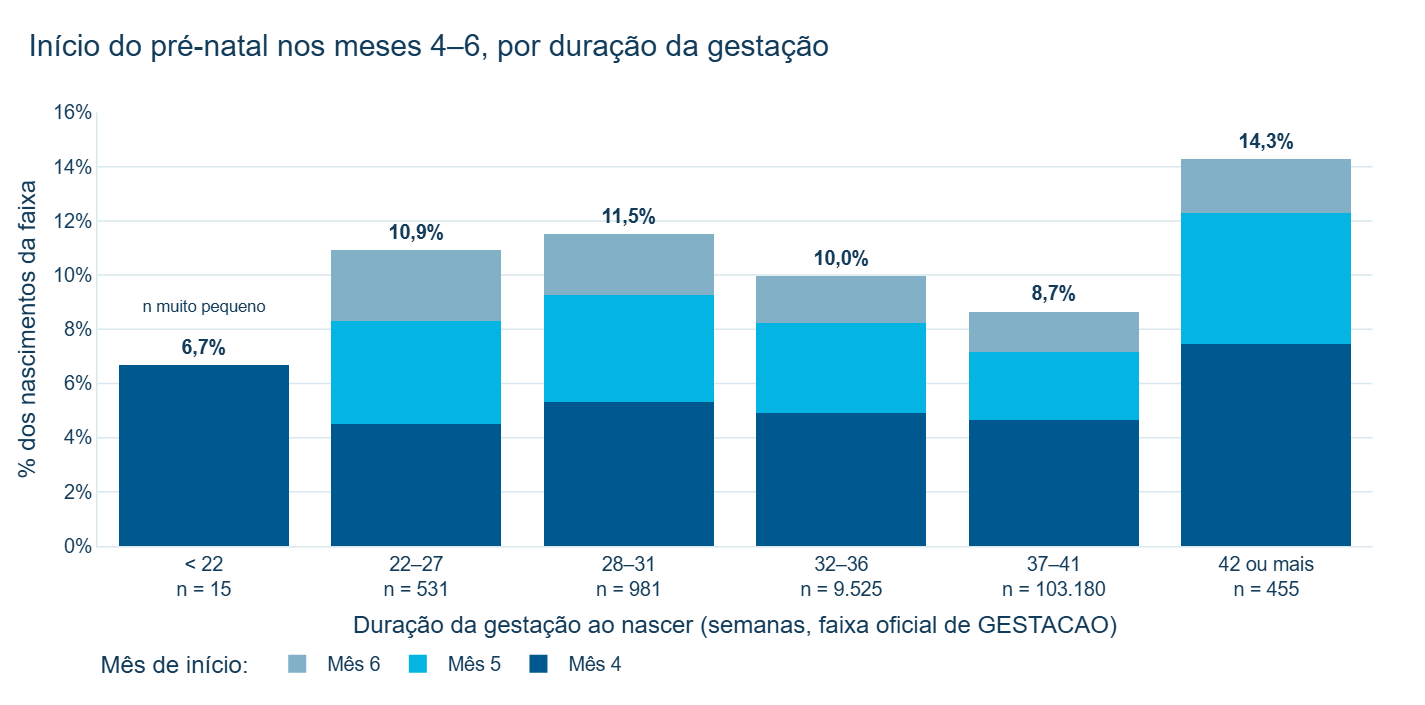

In [7]:
validas = contagens.drop(index=["Total", IGNORADA])
tardios = validas[[4, 5, 6]]
pct_tardio = tardios.div(validas.Total, axis=0) * 100
rotulos = [f"{faixa}<br>n = {fmt(n)}" for faixa, n in validas.Total.items()]
cores = {4: CORES_IPT["AZUL_PRINCIPAL"], 5: CORES_IPT["CIANO"], 6: CORES_IPT["AZUL_CLARO"]}

figura = go.Figure()
for mes in [4, 5, 6]:
    figura.add_bar(x=rotulos, y=pct_tardio[mes], name=f"Mês {mes}", marker_color=cores[mes],
                   customdata=tardios[mes], hovertemplate="%{y:.2f}% (%{customdata} nasc.)<extra></extra>")
total_t0 = pct_tardio.sum(axis=1)
figura.add_scatter(x=rotulos, y=total_t0 + 0.6, mode="text", showlegend=False, hoverinfo="skip",
                   text=[f"<b>{fmt(v, 1)}%</b>" for v in total_t0], textfont=dict(color=CORES_IPT["AZUL_ESCURO"]))
figura.add_annotation(x=rotulos[0], y=total_t0.iloc[0] + 2.2, showarrow=False, font=dict(size=11),
                      text="n muito pequeno")
aplicar_tema_base(figura, "Início do pré-natal nos meses 4–6, por duração da gestação")
figura.update_layout(barmode="stack", width=950, height=470, separators=",.",
                     legend=dict(orientation="h", y=-0.22, x=0, title_text="Mês de início: "))
figura.update_xaxes(title="Duração da gestação ao nascer (semanas, faixa oficial de GESTACAO)")
figura.update_yaxes(title="% dos nascimentos da faixa", range=[0, 16], ticksuffix="%")
exibir_plotly(figura)

**Leitura.** O comparador 4–6 está presente em todas as faixas a partir de 22 semanas, com proporções **iguais ou maiores** que a termo. O início nos meses 4–6 representa cerca de 10,9% dos nascimentos de 22–27 semanas e 8,7% dos de 37–41 semanas. O mês 6 (2,6% contra 1,5%) e o mês 5 (3,8% contra 2,5%) seguem o mesmo padrão. A única faixa sem início nos meses 5 e 6 é a de **menos de 22 semanas**, com só 15 nascimentos. Com a proporção observada a termo, seria esperado menos de um nascimento nesses meses, de modo que a ausência ali não é informativa.

Pela coluna (tabela c), os meses mais tardios têm **mais** prematuros, e não menos. O padrão é o oposto do que se veria se o truncamento dominasse a composição do comparador.

A faixa de 42 semanas ou mais também tem mais inícios tardios (14,3%). Uma explicação plausível, não verificada aqui, é a datação menos precisa quando o pré-natal começa tarde. O padrão reforça a cautela com as fronteiras das faixas.

In [8]:
grupos = {
    "T=1 (meses 1–3)": dados.mes_inicio.le(3),
    "T=0 (meses 4–6)": dados.mes_inicio.ge(4),
    "  meses 4–5": dados.mes_inicio.between(4, 5),
    "  mês 6": dados.mes_inicio.eq(6),
}
com_duracao = dados.semanas.notna()
blocos = {"< 28 semanas": dados.semanas.lt(28), "28–36 semanas": dados.semanas.between(28, 36),
          "37 ou mais": dados.semanas.ge(37)}
composicao = pd.DataFrame({
    nome: {"Nascimentos": int(g.sum()),
           "Com duração conhecida (denominador)": int((g & com_duracao).sum()),
           **{f"% {b}": 100 * (g & m).sum() / (g & com_duracao).sum() for b, m in blocos.items()},
           "Nascimentos < 28 semanas": int((g & dados.semanas.lt(28)).sum())}
    for nome, g in grupos.items()}).T
assert composicao.loc["T=1 (meses 1–3)", "Nascimentos"] + composicao.loc["T=0 (meses 4–6)", "Nascimentos"] == n_total
display(composicao.apply(lambda col: col.map(lambda v: fmt(v, 2 if col.name.startswith("%") else 0))))

,Nascimentos,Com duração conhecida (denominador),% < 28 semanas,% 28–36 semanas,% 37 ou mais,Nascimentos < 28 semanas
T=1 (meses 1–3),104.576,104.571,"0,47","9,03","90,50",487
T=0 (meses 4–6),10.118,10.116,"0,58","10,50","88,92",59
meses 4–5,8.371,8.369,"0,54","10,44","89,02",45
mês 6,1.747,1.747,"0,80","10,76","88,44",14


A tabela acima resume a composição por grupo de comparação. O mês 6, único que a sensibilidade 4–5 removeria, tem composição por duração parecida com a dos meses 4–5 e reúne apenas **14 nascimentos com menos de 28 semanas** (todos de 22–27 semanas).

## 4. Baixo peso segundo a duração da gestação

Esta é só a contextualização da relação entre duração e desfecho. A duração gestacional é registrada no parto e pode ser, ao mesmo tempo, consequência do pré-natal e determinante do peso. **Diferenças condicionadas à duração não são efeitos causais**, e esta seção não as compara entre T = 1 e T = 0.

In [9]:
bp = dados.groupby("faixa").Y.agg(Nascimentos="size", Casos="sum").reindex(ORDEM_FAIXAS)
bp.loc["Total"] = bp.sum()
bp["% com baixo peso (denominador = nascimentos da faixa)"] = 100 * bp.Casos / bp.Nascimentos
bp["% dos casos de baixo peso"] = 100 * bp.Casos / bp.loc["Total", "Casos"]
display(pd.DataFrame({
    "Nascimentos": bp.Nascimentos.map(fmt), "Casos de baixo peso": bp.Casos.map(fmt),
    "% com baixo peso (denominador = nascimentos da faixa)":
        bp["% com baixo peso (denominador = nascimentos da faixa)"].map(lambda v: fmt(v, 2)),
    f"% dos {fmt(bp.loc['Total', 'Casos'])} casos": bp["% dos casos de baixo peso"].map(lambda v: fmt(v, 2)),
}).rename_axis("Duração (semanas)"))

,Nascimentos,Casos de baixo peso,% com baixo peso (denominador = nascimentos da faixa),% dos 9.850 casos
Duração (semanas),,,,
< 22,15,9,"60,00","0,09"
22–27,531,504,"94,92","5,12"
28–31,981,904,"92,15","9,18"
32–36,9.525,4.574,"48,02","46,44"
37–41,103.180,3.843,"3,72","39,02"
42 ou mais,455,16,"3,52","0,16"
Ignorada,7,0,"0,00","0,00"
Total,114.694,9.850,"8,59","100,00"


O baixo peso é quase universal abaixo de 32 semanas (acima de 90% de 22 a 31 semanas), atinge cerca de 48% em 32–36 semanas e fica em torno de 3,7% a termo. Os 546 nascimentos com menos de 28 semanas (0,5% da população) concentram cerca de 5% dos casos de baixo peso. Assim, qualquer desequilíbrio do comparador **nessas faixas** pesa no desfecho de forma desproporcional ao seu tamanho, mas a fatia é pequena.

O gráfico a seguir acrescenta o que a tabela não mostra: para cada **mês de início**, quanto do risco bruto de baixo peso vem de nascimentos pré-termo (< 37 semanas) e quanto vem de nascimentos a termo. É uma decomposição contábil, com o denominador igual aos nascimentos do mês com duração conhecida. Não é uma análise de mediação.

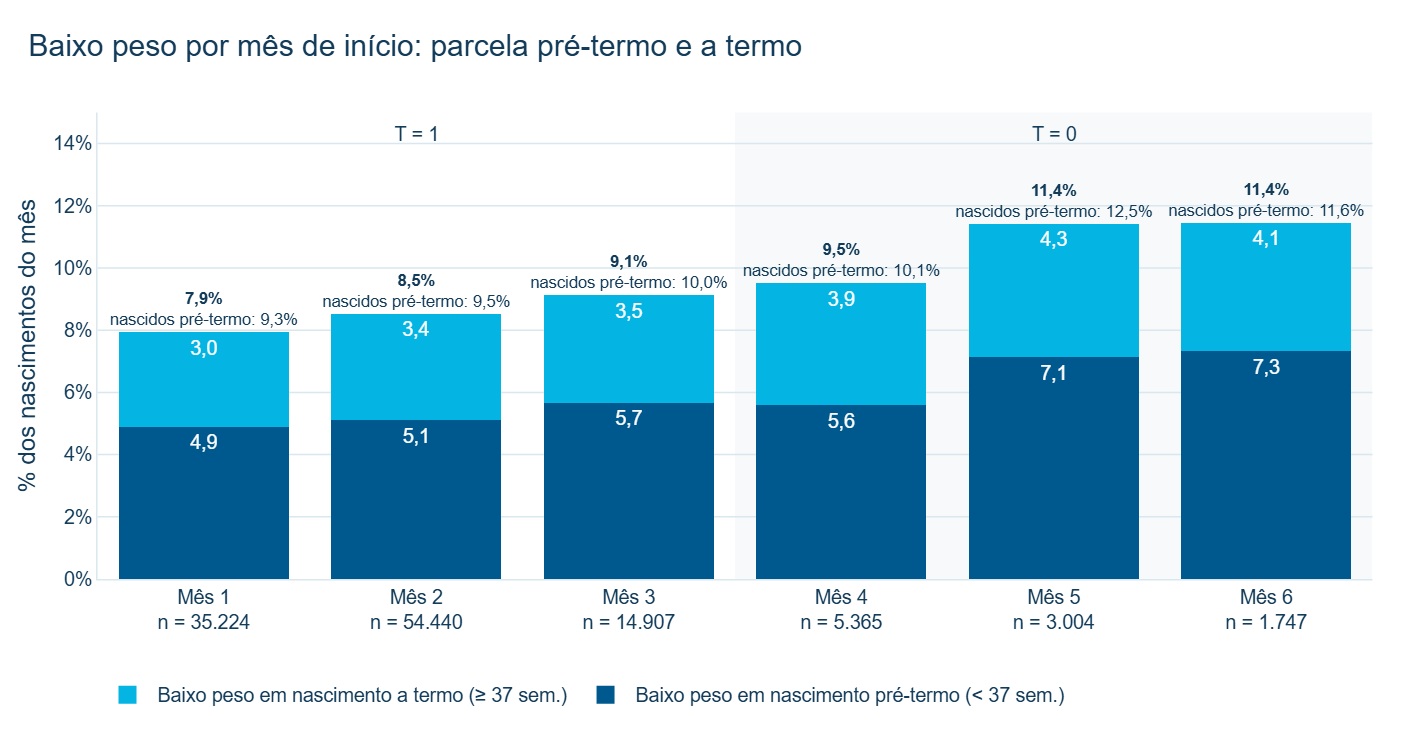

In [10]:
base = dados[com_duracao]
n_mes = base.groupby("mes_inicio").size()
pre = base[base.semanas.lt(37)].groupby("mes_inicio").Y.sum().reindex(MESES, fill_value=0) / n_mes * 100
termo = base[base.semanas.ge(37)].groupby("mes_inicio").Y.sum().reindex(MESES, fill_value=0) / n_mes * 100
pct_pre = base.groupby("mes_inicio").semanas.apply(lambda s: s.lt(37).mean() * 100)
assert ((pre + termo) - base.groupby("mes_inicio").Y.mean() * 100).abs().max() < 1e-9

rotulos_mes = [f"Mês {m}<br>n = {fmt(n_mes[m])}" for m in MESES]
figura = go.Figure()
figura.add_bar(x=rotulos_mes, y=pre, name="Baixo peso em nascimento pré-termo (< 37 sem.)",
               marker_color=CORES_IPT["AZUL_PRINCIPAL"], text=[fmt(v, 1) for v in pre],
               textposition="inside", textfont=dict(color="white"))
figura.add_bar(x=rotulos_mes, y=termo, name="Baixo peso em nascimento a termo (≥ 37 sem.)",
               marker_color=CORES_IPT["CIANO"], text=[fmt(v, 1) for v in termo],
               textposition="inside", textfont=dict(color="white"))
figura.add_scatter(x=rotulos_mes, y=pre + termo + 0.7, mode="text", showlegend=False, hoverinfo="skip",
                   text=[f"<b>{fmt(v, 1)}%</b><br>nascidos pré-termo: {fmt(p, 1)}%" for v, p in zip(pre + termo, pct_pre)],
                   textfont=dict(size=11, color=CORES_IPT["AZUL_ESCURO"]))
figura.add_vrect(x0=2.5, x1=5.5, fillcolor=CORES_IPT["CINZA_FUNDO"], opacity=0.8, line_width=0, layer="below")
figura.add_annotation(x=1, y=14.3, text="T = 1", showarrow=False, font=dict(size=13))
figura.add_annotation(x=4, y=14.3, text="T = 0", showarrow=False, font=dict(size=13))
aplicar_tema_base(figura, "Baixo peso por mês de início: parcela pré-termo e a termo")
figura.update_layout(barmode="stack", width=950, height=490, separators=",.",
                     legend=dict(orientation="h", y=-0.2, x=0))
figura.update_yaxes(title="% dos nascimentos do mês", range=[0, 15], ticksuffix="%")
exibir_plotly(figura)

**Leitura.** O risco bruto de baixo peso cresce do mês 1 (7,9%) ao mês 6 (11,4%). A fração pré-termo também cresce, de 9,3% para 11,6–12,5% nos meses 5–6, e a parcela do baixo peso vinda de nascimentos pré-termo segue esse movimento. A duração gestacional, portanto, **difere entre os grupos** que formam o contraste. É exatamente por isso que ela não pode ser usada para "igualar" os grupos: condicionar na duração compararia nascimentos selecionados por uma variável que pode estar no caminho entre pré-natal e peso.

## 5. Interpretação metodológica

*Nota de revisão.* Os trechos interpretativos desta seção foram ajustados para ficarem coerentes com a seção 5.1 e com a conclusão (seção 6). A versão anterior afirmava que a restrição temporal não aparecia empiricamente, que ficaria confinada a menos de 0,5% da população e que uma sensibilidade 4–5 acrescentaria pouco. Essas leituras não se sustentam, porque as tabelas das seções 2 a 4 descrevem apenas a população já selecionada por início nos meses 1–6. Códigos, tabelas, gráficos e números não foram alterados.

**Há evidência de restrição temporal na composição dos grupos?** A restrição existe por construção. Dentro do recorte 1–6, a composição não mostra o padrão que o truncamento produziria sozinho: os meses 4–6 têm proporção igual ou maior de nascimentos de 22–27 semanas e uma fração pré-termo maior. A ausência de inícios nos meses 5–6 só ocorre abaixo de 22 semanas, com 15 nascimentos, número pequeno demais para ter significado. Essa leitura, porém, **não afasta o problema**. A composição observada mistura truncamento, perfis de risco diferentes entre quem inicia cedo e tarde e o possível efeito do próprio pré-natal sobre a duração, e refere-se somente a registros que já passaram pelo filtro de início. A seção 5.1 mostra **diferenças de composição entre registros incluídos e excluídos** de B: 43 dos 2.728 excluídos têm menos de 28 semanas (1,58%), contra 546 dos 114.694 incluídos (0,48%).

**Em quais durações a comparação fica especialmente limitada?** Nas gestações que terminam **antes do fim do 6º mês**. Para as demais, os seis meses foram vividos e qualquer início entre 1 e 6 era possível. Nas faixas oficiais, isso abrange **< 22 semanas** (sem oportunidade para os meses finais) e parte de **22–27 semanas**, a faixa em que, pelas convenções usuais, cai a fronteira do 6º mês (sem fixar a semana exata). Juntas, as duas somam 546 nascimentos (0,48%), sendo 59 no grupo T = 0. A partir de 28 semanas a oportunidade de iniciar em qualquer mês de 1 a 6 está completa. A proporção de 0,48% descreve a população já selecionada; **não demonstra que o viés seja pequeno** nem limita o possível viés a essa fração.

**O comparador 4–6 continua sujeito ao problema?** Sim, sobretudo pelo mês 6. Na formulação A (4º–9º), a oportunidade incompleta de início atingia todas as gestações pré-termo, ou seja, 28–36 semanas e não só < 28; no 4º–6º, a parcela de **incluídos** nessa situação é menor. Isso não equivale a confinar o viés a essa parcela. A maior concentração de gestações curtas entre os excluídos (seção 5.1) indica seleção anterior à comparação, mas **não identifica a magnitude nem a direção do viés causal**. Um mecanismo possível, que estes dados não permitem verificar: a gestante cuja gestação terminou antes do mês em que ela iniciaria o pré-natal pode ter sido registrada sem pré-natal, com início ignorado ou com início fora de 1–6. Nesse caso ela sai da população por seleção, e não muda de grupo.

**O que os resultados permitem e o que não permitem concluir?** Permitem **descrever** a disponibilidade da duração gestacional, a composição de cada mês de início, a concentração do baixo peso nas durações curtas e as diferenças de composição entre incluídos e excluídos. **Não** permitem estimar o tamanho nem o sinal de um viés de truncamento ou de seleção, nem afirmar que ele seja pequeno. Também não autorizam ler diferenças dentro de cada faixa como efeitos causais, nem justificam acrescentar a duração ao ajuste, porque ela é registrada no parto e pode ser mediadora ou variável de seleção. **A duração gestacional permanece fora do ajuste principal.**

**Vale considerar a comparação 4–5 como sensibilidade futura?** Remover o mês 6 retiraria 1.747 nascimentos (17% de T = 0), dos quais 14 têm menos de 28 semanas, e a composição do mês 6 por duração é próxima à dos meses 4–5. Esses números descrevem o que a sensibilidade removeria, mas **não permitem afirmar que ela corrigiria o problema**, nem que acrescentaria pouco. Ela continuaria restrita aos incluídos em B, não alcançaria a seleção anterior ao filtro de início (2.728 registros fora de B), e uma mudança na estimativa misturaria perda de amostra, perfil de quem inicia no mês 6 e eventual efeito do truncamento. Se for realizada, deve ser lida como análise de sensibilidade, não como correção.

## 5.1. Complemento: nascimentos fora da especificação B

**Descrição da seleção observada.** Fonte: `data/processed/sinasc_2024.parquet`; unidade = nascimento registrado. Mantêm-se ano de nascimento 2024 (`DTNASC`), residência materna em São Paulo (`CODMUNRES = 355030`), gestação única e peso de 500 a 6.000 g, **sem filtrar inicialmente `MESPRENAT`**. A seção é autônoma e não executa modelos nem reestima resultados anteriores.

Conforme o [dicionário local](../../docs/dados/DICIONARIO_ANALITICO_SINASC_2024.md), meses 1–3 e 4–6 formam B; 7–9 identificam início após o sexto mês; `99` é ignorado. Nulos/vazios e outros códigos ficam na categoria de informação ausente, ignorada ou outra. **Ausência de informação não significa ausência de atendimento pré-natal.** A duração usa as faixas oficiais de `GESTACAO`: 1 = < 22; 2 = 22–27; 3–4 = 28–36; 5–6 = 37 ou mais; nulo/9/outros = desconhecida. Não se imputam semanas a partir de outro campo.

**Denominadores:** cada célula gestacional mostra **n (% do N da linha)**, incluindo duração desconhecida no denominador. A coluna < 28 soma as duas primeiras faixas, não sendo uma categoria adicional. “% do total” usa todos os 117.422 nascimentos antes do filtro de início. As quatro primeiras linhas são categorias exclusivas; as seguintes são subtotais e total, que não devem ser somados novamente.

In [11]:
# Complemento autônomo: executar com a .venv do projeto, sem refazer células anteriores.
from pathlib import Path
import duckdb
import pandas as pd
from IPython.display import display

cwd_complemento = Path.cwd().resolve()
raiz_complemento = next(
    p for p in [cwd_complemento, *cwd_complemento.parents]
    if (p / "data/processed/sinasc_2024.parquet").is_file()
)
parquet_complemento = raiz_complemento / "data/processed/sinasc_2024.parquet"
categorias_complemento = [
    "Início nos meses 1–3",
    "Início nos meses 4–6",
    "Início nos meses 7–9",
    "Ausente, ignorada ou outra",
]
faixas_complemento = ["< 22", "22–27", "28–36", "37 ou mais", "Desconhecida"]

# Agregação em DuckDB: nenhum filtro inicial por MESPRENAT.
with duckdb.connect() as con_complemento:
    resumo_complemento = con_complemento.execute("""
        WITH recorte AS (
            SELECT
                nullif(trim(MESPRENAT), '') AS mes_bruto,
                try_cast(MESPRENAT AS INTEGER) AS mes,
                try_cast(GESTACAO AS INTEGER) AS gestacao
            FROM read_parquet(?)
            WHERE CODMUNRES = '355030'
              AND try_cast(GRAVIDEZ AS INTEGER) = 1
              AND try_cast(PESO AS INTEGER) BETWEEN 500 AND 6000
              AND year(try_strptime(DTNASC, '%d%m%Y')) = 2024
        ),
        classificado AS (
            SELECT *,
                CASE
                    WHEN mes BETWEEN 1 AND 3 THEN 'Início nos meses 1–3'
                    WHEN mes BETWEEN 4 AND 6 THEN 'Início nos meses 4–6'
                    WHEN mes BETWEEN 7 AND 9 THEN 'Início nos meses 7–9'
                    ELSE 'Ausente, ignorada ou outra'
                END AS categoria
            FROM recorte
        )
        SELECT categoria,
            count(*) AS n,
            count(*) FILTER (WHERE gestacao = 1) AS "< 22",
            count(*) FILTER (WHERE gestacao = 2) AS "22–27",
            count(*) FILTER (WHERE gestacao IN (3, 4)) AS "28–36",
            count(*) FILTER (WHERE gestacao IN (5, 6)) AS "37 ou mais",
            count(*) FILTER (
                WHERE gestacao IS NULL OR gestacao NOT BETWEEN 1 AND 6
            ) AS "Desconhecida",
            count(*) FILTER (WHERE mes_bruto IS NULL) AS inicio_ausente,
            count(*) FILTER (WHERE mes = 99) AS inicio_ignorado,
            count(*) FILTER (
                WHERE mes_bruto IS NOT NULL
                  AND (mes IS NULL OR (mes NOT BETWEEN 1 AND 9 AND mes <> 99))
            ) AS inicio_outro
        FROM classificado
        GROUP BY categoria
    """, [parquet_complemento.as_posix()]).df()

resumo_complemento = (
    resumo_complemento.set_index("categoria")
    .reindex(categorias_complemento, fill_value=0)
)
n_complemento = int(resumo_complemento.n.sum())
assert n_complemento > 0
assert resumo_complemento.loc[categorias_complemento[:2], "n"].tolist() == [104_576, 10_118]
assert resumo_complemento[faixas_complemento].sum(axis=1).eq(resumo_complemento.n).all()
assert (
    resumo_complemento[["inicio_ausente", "inicio_ignorado", "inicio_outro"]].to_numpy().sum()
    == resumo_complemento.loc[categorias_complemento[3], "n"]
)

# Subtotais são sobreposições das quatro categorias, não novas observações.
cruzada_complemento = resumo_complemento[["n", *faixas_complemento]].copy()
cruzada_complemento.loc["Incluídos em B (1–6)"] = cruzada_complemento.iloc[:2].sum()
cruzada_complemento.loc["Fora de B"] = cruzada_complemento.loc[categorias_complemento[2:]].sum()
cruzada_complemento.loc["Total antes do filtro"] = cruzada_complemento.loc[categorias_complemento].sum()
cruzada_complemento["< 28"] = cruzada_complemento["< 22"] + cruzada_complemento["22–27"]
assert int(cruzada_complemento.loc["Incluídos em B (1–6)", "< 28"]) == 546
assert int(cruzada_complemento.loc[["Incluídos em B (1–6)", "Fora de B"], "n"].sum()) == n_complemento
assert int(cruzada_complemento.loc[["Incluídos em B (1–6)", "Fora de B"], "< 28"].sum()) == int(
    cruzada_complemento.loc["Total antes do filtro", "< 28"]
)

def fmt_complemento(valor, casas=0):
    return f"{valor:,.{casas}f}".replace(",", "_").replace(".", ",").replace("_", ".")

tabela_complemento = pd.DataFrame(index=cruzada_complemento.index)
tabela_complemento["N (denominador da linha)"] = cruzada_complemento.n.map(fmt_complemento)
tabela_complemento["% do total"] = (100 * cruzada_complemento.n / n_complemento).map(
    lambda v: fmt_complemento(v, 2)
)
for faixa in [*faixas_complemento, "< 28"]:
    tabela_complemento[f"{faixa} sem. | n (%)" if faixa != "Desconhecida" else "Desconhecida | n (%)"] = [
        f"{fmt_complemento(n)} ({fmt_complemento(100 * n / denominador, 2)}%)"
        if denominador else "0 (não calculável)"
        for n, denominador in zip(cruzada_complemento[faixa], cruzada_complemento.n)
    ]
with pd.option_context("display.max_columns", None, "display.width", 200):
    display(tabela_complemento.rename_axis("Início do pré-natal / subtotal"))

fora_complemento = cruzada_complemento.loc["Fora de B"]
dentro_complemento = cruzada_complemento.loc["Incluídos em B (1–6)"]
print(
    f"Fora de B: {fmt_complemento(fora_complemento['n'])}/{fmt_complemento(n_complemento)} "
    f"({fmt_complemento(100 * fora_complemento['n'] / n_complemento, 2)}%). "
    f"Menos de 28 semanas: {fmt_complemento(fora_complemento['< 28'])} fora de B; "
    f"{fmt_complemento(dentro_complemento['< 28'])} em B; "
    f"{fmt_complemento(cruzada_complemento.loc['Total antes do filtro', '< 28'])} no total."
)
print(
    "Detalhe da informação de início: "
    f"{fmt_complemento(resumo_complemento.inicio_ausente.sum())} ausentes; "
    f"{fmt_complemento(resumo_complemento.inicio_ignorado.sum())} ignorados (99); "
    f"{fmt_complemento(resumo_complemento.inicio_outro.sum())} outros códigos."
)
print("Totalizações conferidas; os 114.694 incluídos e seus 546 registros < 28 semanas foram reconciliados.")


,N (denominador da linha),% do total,< 22 sem. | n (%),22–27 sem. | n (%),28–36 sem. | n (%),37 ou mais sem. | n (%),Desconhecida | n (%),< 28 sem. | n (%)
Início do pré-natal / subtotal,,,,,,,,
Início nos meses 1–3,104.576,"89,06","14 (0,01%)","473 (0,45%)","9.444 (9,03%)","94.640 (90,50%)","5 (0,00%)","487 (0,47%)"
Início nos meses 4–6,10.118,"8,62","1 (0,01%)","58 (0,57%)","1.062 (10,50%)","8.995 (88,90%)","2 (0,02%)","59 (0,58%)"
Início nos meses 7–9,1.735,"1,48","0 (0,00%)","3 (0,17%)","179 (10,32%)","1.552 (89,45%)","1 (0,06%)","3 (0,17%)"
"Ausente, ignorada ou outra",993,"0,85","1 (0,10%)","39 (3,93%)","217 (21,85%)","734 (73,92%)","2 (0,20%)","40 (4,03%)"
Incluídos em B (1–6),114.694,"97,68","15 (0,01%)","531 (0,46%)","10.506 (9,16%)","103.635 (90,36%)","7 (0,01%)","546 (0,48%)"
Fora de B,2.728,"2,32","1 (0,04%)","42 (1,54%)","396 (14,52%)","2.286 (83,80%)","3 (0,11%)","43 (1,58%)"
Total antes do filtro,117.422,"100,00","16 (0,01%)","573 (0,49%)","10.902 (9,28%)","105.921 (90,21%)","10 (0,01%)","589 (0,50%)"


Fora de B: 2.728/117.422 (2,32%). Menos de 28 semanas: 43 fora de B; 546 em B; 589 no total.
Detalhe da informação de início: 889 ausentes; 104 ignorados (99); 0 outros códigos.
Totalizações conferidas; os 114.694 incluídos e seus 546 registros < 28 semanas foram reconciliados.


**Interpretação.** Dos **117.422** nascimentos no recorte anterior ao filtro de início, **2.728 (2,32%)** ficam fora de B: 1.735 nos meses 7–9 e 993 com informação ausente/ignorada (889 ausentes e 104 com código 99; nenhum outro código observado). Há **43 registros com menos de 28 semanas entre os excluídos (1,58%)**, contra **546/114.694 (0,48%)** entre os incluídos; no total ampliado, são **589/117.422 (0,50%)**. A duração é desconhecida em 3 excluídos e 7 incluídos, mantidos nos denominadores.

Existe maior concentração observada de gestações curtas entre os excluídos **em conjunto**, mas o padrão difere por categoria: **40/993 (4,03%)** no grupo sem início informado/ignorado e **3/1.735 (0,17%)** nos meses 7–9. Isso descreve composição e seleção observada; não demonstra que o viés temporal seja grande, pequeno ou tenha determinada direção. O recorte continua restrito aos **nascidos vivos registrados** e não recupera gestações terminadas em óbito fetal.

**Execução:** apenas esta seção complementar, com totalização das categorias/faixas e reconciliação dos 114.694 incluídos e dos 546 registros < 28 semanas. Resultados anteriores preservados.

## 6. Conclusão

**Os dados descrevem diferenças de composição e seleção observada, mas não identificam a magnitude nem a direção do viés causal temporal.** Os 546 nascimentos com menos de 28 semanas (0,48%) pertencem à população já selecionada por início nos meses 1–6; essa proporção **não limita o possível viés a 0,48%**. Antes desse filtro, há 117.422 nascimentos; 2.728 (2,32%) ficam fora de B, dos quais 43 (1,58%) têm menos de 28 semanas. A maior concentração entre os excluídos se concentra na informação de início ausente/ignorada e **não demonstra, por si só, viés grande**.

Esta conclusão substitui a interpretação anterior da seção 5 de que a restrição estaria confinada a menos de 0,5% da população e de que uma sensibilidade 4–5 acrescentaria pouco. A presença de gestações curtas no comparador 4–6 e a pequena proporção nos incluídos não afastam seleção anterior à comparação. Não se pode inferir, com estas tabelas, ausência de viés, seu tamanho/sinal ou a capacidade de uma sensibilidade de corrigi-lo.

A concordância entre `GESTACAO` e `SEMAGESTAC` observada na população B é **consistência entre campos**, não validação independente da idade gestacional nem garantia de precisão da medida. Informação de início ausente/ignorada não equivale a ausência de pré-natal. A análise abrange apenas **nascidos vivos registrados**, sem recuperar óbitos fetais.

A especificação principal e os resultados anteriores permanecem preservados; não foram executados novos modelos ou sensibilidades. A duração gestacional, registrada no parto e potencialmente mediadora ou variável de seleção, permanece fora do conjunto de ajuste.